# France - Point par point

Paris listings with some hand-made "dots" mixed in. Goal: find them, split them into letters, read the word.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from skimage.morphology import skeletonize

pd.set_option('display.width', 200)
df = pd.read_csv('../task_france/paris_listings.csv')
df.shape

(28108, 18)

## EDA

In [2]:
df.info()
df.isna().sum()[lambda s: s > 0]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28108 entries, 0 to 28107
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   listing_id                      28108 non-null  int64  
 1   neighbourhood                   28108 non-null  object 
 2   room_type                       28108 non-null  object 
 3   property_type                   28108 non-null  object 
 4   latitude                        28108 non-null  float64
 5   longitude                       28108 non-null  float64
 6   accommodates                    28108 non-null  int64  
 7   bedrooms                        28103 non-null  float64
 8   beds                            27175 non-null  float64
 9   price                           28108 non-null  float64
 10  minimum_nights                  28010 non-null  float64
 11  availability_365                28108 non-null  int64  
 12  number_of_reviews               

bedrooms            5
beds              933
minimum_nights     98
dtype: int64

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
listing_id,28108.0,5506013.93,2599772.20,1000358.00,3254931.50,5514730.50,7775756.00,9999630.00
latitude,28108.0,48.86,0.02,48.82,48.85,48.86,48.88,48.90
longitude,28108.0,2.34,0.03,2.23,2.32,2.35,2.36,2.46
accommodates,28108.0,3.39,1.83,1.00,2.00,3.00,4.00,16.00
bedrooms,28103.0,1.27,0.89,0.00,1.00,1.00,2.00,33.00
beds,27175.0,1.90,1.16,1.00,1.00,2.00,2.00,30.00
price,28108.0,271.68,200.75,40.00,142.00,214.00,332.67,1500.00
minimum_nights,28010.0,5.75,18.48,1.00,1.00,2.00,3.00,365.00
availability_365,28108.0,192.21,118.83,0.00,77.00,212.00,306.00,365.00
number_of_reviews,28108.0,55.70,90.66,1.00,9.00,27.00,65.00,4760.00


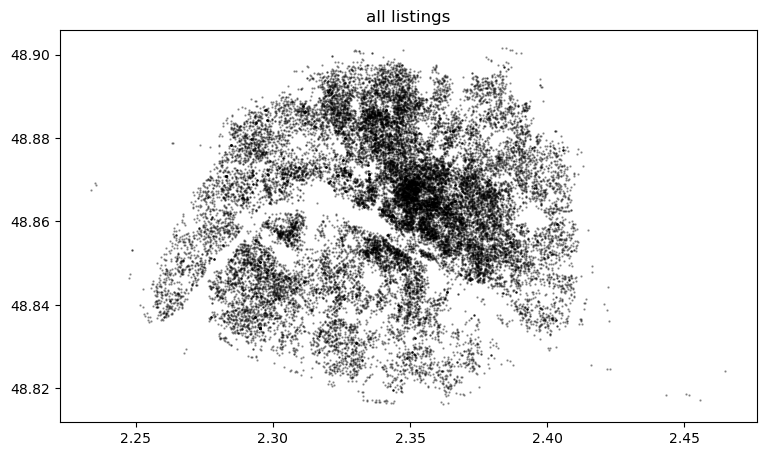

In [4]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(df.longitude, df.latitude, s=0.4, c='k', alpha=0.4)
ax.set_aspect(1 / np.cos(np.radians(48.86)))
ax.set_title('all listings')
plt.show()

Nothing odd on the map and nothing odd column by column: no constant values, no impossible combinations (ltm <= total reviews everywhere, room type matches property type, neighbourhood matches coordinates). Missing values (beds, minimum_nights, bedrooms) are mostly hotel rooms and are not the injected rows.

What gave the fakes away: pairs of rows with identical integer fields (room/property type, capacity, beds, minimum nights, review count, ltm, rating, host count) a few hundred metres apart, with price / availability / reviews_per_month only slightly different. Single-listing hosts show up twice, which can't be real.

In [5]:
key_cols = ['room_type', 'property_type', 'accommodates', 'bedrooms', 'beds', 'minimum_nights',
            'number_of_reviews', 'number_of_reviews_ltm', 'host_is_superhost',
            'calculated_host_listings_count', 'review_scores_rating']
key = df[key_cols].astype(str).agg('|'.join, axis=1)
size = key.map(key.value_counts())
pairs = df[(size == 2) & (df.number_of_reviews >= 100) & (df.calculated_host_listings_count == 1)]
pairs.assign(key=key).sort_values('key')[['listing_id', 'latitude', 'longitude', 'price', 'availability_365',
                                         'reviews_per_month', 'number_of_reviews', 'number_of_reviews_ltm']].head(12)

,listing_id,latitude,longitude,price,availability_365,reviews_per_month,number_of_reviews,number_of_reviews_ltm
687,9325331,48.87414,2.34092,496.33,57,2.83,337,16
5817,1643658,48.87277,2.34277,489.30,37,3.00,337,16
11683,8073520,48.86367,2.38049,156.50,315,1.48,161,16
6658,8924591,48.86292,2.36688,154.00,325,1.43,161,16
13527,2006743,48.85710,2.36952,159.00,338,1.27,126,12
14560,7709534,48.86324,2.37321,155.83,320,1.32,126,12
18811,2523837,48.88212,2.32041,147.00,270,0.90,118,12
18572,3552366,48.88272,2.32358,151.00,254,0.89,118,12
12481,1489101,48.88795,2.31570,118.50,294,1.17,111,1
8138,2625580,48.88549,2.31353,115.83,299,1.15,111,1


Following these rows across the map, price, availability and reviews_per_month drift smoothly with position, like a colour gradient. So the injected dots sit on thin sheets in the joint space (lon, lat, price, availability, reviews_per_month), while real listings are scattered in it.

Detection: put the five columns on comparable scales (~300 m, 8 % of price, 15 days, 8 % of reviews/month) and take the distance to the 3rd nearest neighbour.

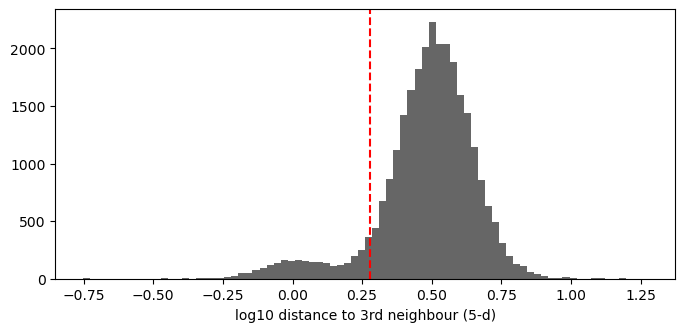

In [6]:
def embed(x):
    return np.c_[x.longitude * 73 / 0.3,          # km east / 0.3
                 x.latitude * 111 / 0.3,          # km north / 0.3
                 np.log(x.price) / 0.08,
                 x.availability_365 / 15,
                 np.log(x.reviews_per_month) / 0.08]

Z = embed(df)
d3 = cKDTree(Z).query(Z, k=4)[0][:, 3]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(d3), bins=80, color='0.4')
ax.axvline(np.log10(1.9), c='r', ls='--')
ax.set_xlabel('log10 distance to 3rd neighbour (5-d)')
plt.show()

Clearly bimodal, valley around 1.3-1.5. I cut at 1.9 (dashed) so the letters come out complete; the real listings that slip in are removed in the next steps.

2705 candidates


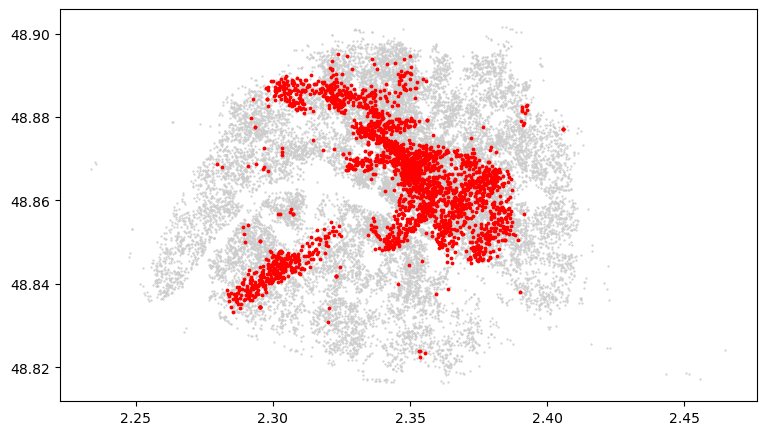

In [7]:
cand = d3 < 1.9
print(cand.sum(), 'candidates')
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(df.longitude, df.latitude, s=0.3, c='0.8')
ax.scatter(df.longitude[cand], df.latitude[cand], s=3, c='r')
ax.set_aspect(1 / np.cos(np.radians(48.86)))
plt.show()

On the map the candidates overlap into a tangle, so the letters are not drawn in lat/lon. Cluster them in the same 5-d space.

In [8]:
lab = np.full(len(df), -1)
lab[cand] = DBSCAN(eps=2.5, min_samples=4).fit_predict(Z[cand])
counts = pd.Series(lab[lab >= 0]).value_counts()
counts.head(10)

1     370
3     368
2     334
0     311
5     304
4     280
6     231
9      26
32     12
14     11
Name: count, dtype: int64

In [9]:
def plane(g):
    W = np.c_[g.longitude, g.latitude, np.log(g.price), g.availability_365, np.log(g.reviews_per_month)]
    W = (W - W.mean(0)) / W.std(0)
    return W, PCA(5).fit(W)

rows = []
for c in counts[counts >= 100].index:
    g = df[lab == c]
    rows.append((c, len(g), g.longitude.mean().round(3), plane(g)[1].explained_variance_ratio_[:2].sum().round(3)))
tab = pd.DataFrame(rows, columns=['cluster', 'n', 'lon_mean', 'var_2pc'])
tab

,cluster,n,lon_mean,var_2pc
0,1,370,2.375,0.911
1,3,368,2.363,0.948
2,2,334,2.339,0.943
3,0,311,2.301,0.959
4,5,304,2.319,0.943
5,4,280,2.352,0.920
6,6,231,2.352,0.541


Six groups are flat: two principal components explain ~95 % of their variance, i.e. each is a 2-d drawing pushed into the five columns by a linear map (a different map per letter). The seventh group is not flat (~55 %): it is the dense 2nd/3rd arrondissement, real listings, dropped.

In [10]:
letters_cl = tab[tab.var_2pc > 0.85].cluster.tolist()
df['cluster'] = np.where(np.isin(lab, letters_cl), lab, -1)
fake = df[df.cluster >= 0].copy()
print(len(fake), 'injected listings in', len(letters_cl), 'letters')

1967 injected listings in 6 letters


Reading a letter: PCA to 2-d and whiten. Whitening removes scale and shear, so between the drawing and an upright glyph only a rotation is left (no mirror is needed). Every cluster is matched against skeletons of A-Z (DejaVu Sans) over all rotations, scored by symmetric chamfer distance (lower is better).

In [11]:
def whiten(X):
    X = X - X.mean(0)
    w, V = np.linalg.eigh(np.cov(X.T))
    return X @ V @ np.diag(1 / np.sqrt(w)) @ V.T

def glyph(ch):
    fig = plt.figure(figsize=(2, 2), dpi=100)
    fig.text(0.5, 0.5, ch, fontsize=110, ha='center', va='center', family='DejaVu Sans')
    fig.canvas.draw()
    im = np.asarray(fig.canvas.buffer_rgba())[:, :, 0]
    plt.close(fig)
    yy, xx = np.nonzero(skeletonize(im < 128))
    return whiten(np.c_[xx, -yy].astype(float))

def letter_2d(g):
    W, _ = plane(g)
    U, s, _ = np.linalg.svd(W, full_matrices=False)
    return whiten(U[:, :2] * s[:2])

def rot(t):
    return np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])

def match(D, T):
    tD = cKDTree(D)
    best = (9, 0)
    for t in np.radians(np.arange(0, 360, 2)):
        Y = T @ rot(t).T
        e = tD.query(Y)[0].mean() + cKDTree(Y).query(D)[0].mean()
        best = min(best, (e, t))
    return best

alphabet = 'ABCDEFGHJKLMNOPQRSTUVWXYZ'
G = {ch: glyph(ch) for ch in alphabet}
pts = {c: letter_2d(fake[fake.cluster == c]) for c in letters_cl}
fits = {c: sorted((round(match(pts[c], G[ch])[0], 3), ch) for ch in alphabet) for c in letters_cl}
pd.DataFrame({c: [f'{ch} {e}' for e, ch in fits[c][:5]] for c in letters_cl}).T

,0,1,2,3,4
1,U 0.196,C 0.263,R 0.291,B 0.322,G 0.332
3,O 0.173,D 0.186,Q 0.19,C 0.234,G 0.242
2,Z 0.159,N 0.166,H 0.258,M 0.281,R 0.354
0,R 0.246,B 0.324,H 0.351,M 0.356,N 0.368
5,E 0.201,M 0.286,W 0.289,B 0.317,S 0.376
4,A 0.33,W 0.369,P 0.383,R 0.398,V 0.404


Per group: R, U, N/Z (tie: the same zigzag turned 90 degrees), O/D (almost tied), A (W close behind), E.
The open group has two straight parallel arms, so U rather than C; the ring has one flatter side, which is why D fits as well as O.

The six groups are read with the fitted rotation of the chosen glyph below.

In [12]:
pick = {}
for c in letters_cl:
    top = [ch for _, ch in fits[c][:2]]
    pick[c] = 'N' if set(top) == {'N', 'Z'} else ('D' if set(top) == {'O', 'D'} else top[0])
pick

{1: 'U', 3: 'D', 2: 'N', 0: 'R', 5: 'E', 4: 'A'}

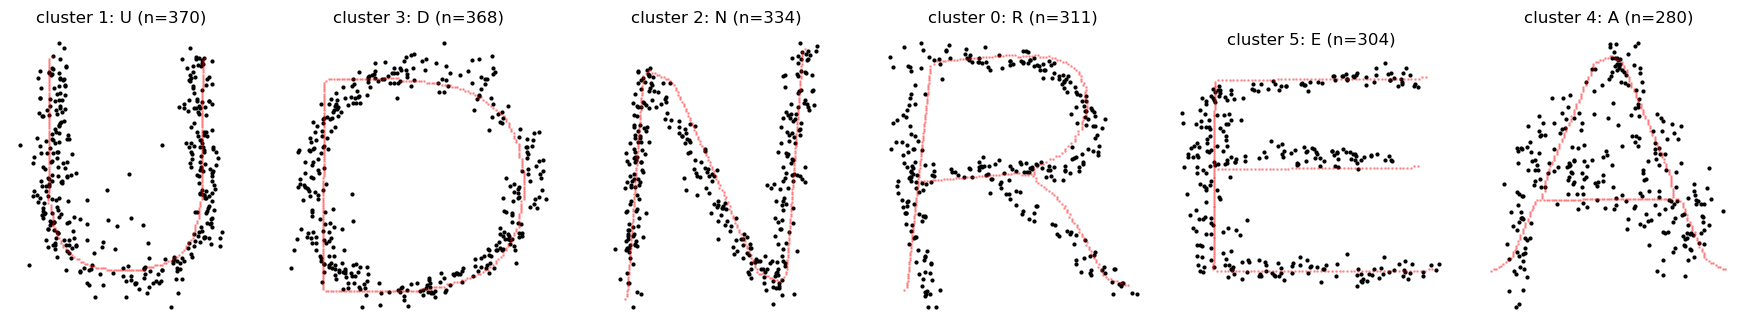

In [13]:
def upright(c):
    e, t = match(pts[c], G[pick[c]])
    return pts[c] @ rot(t)

fig, axs = plt.subplots(1, len(letters_cl), figsize=(3 * len(letters_cl), 3.4))
for a, c in zip(axs, letters_cl):
    V = upright(c)
    a.scatter(V[:, 0], V[:, 1], s=4, c='k')
    a.scatter(G[pick[c]][:, 0], G[pick[c]][:, 1], s=1, c='r', alpha=0.3)
    a.set_aspect('equal'); a.axis('off')
    a.set_title(f'cluster {c}: {pick[c]} (n={(fake.cluster == c).sum()})')
plt.tight_layout()
plt.show()
for c in letters_cl:
    V = upright(c)
    fig, ax = plt.subplots(figsize=(3.5, 3.5))
    ax.scatter(V[:, 0], V[:, 1], s=6, c='k')
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'cluster {c}: {pick[c]}')
    plt.savefig(f'letter_{pick[c]}.png', dpi=120, bbox_inches='tight')
    plt.close(fig)

Letters: R, U, N, D, A, E. Nothing in the data fixes the order: centroids in any column, listing ids, row order, group sizes and missing-value counts give no word. West to east the groups read R E N A D U.
The only English word these six make is UNREAD. Other readings, if one letter is taken from its runner-up fit: DANCER / CRANED (U->C), CORNEA / CANOER (U->C, D->O).

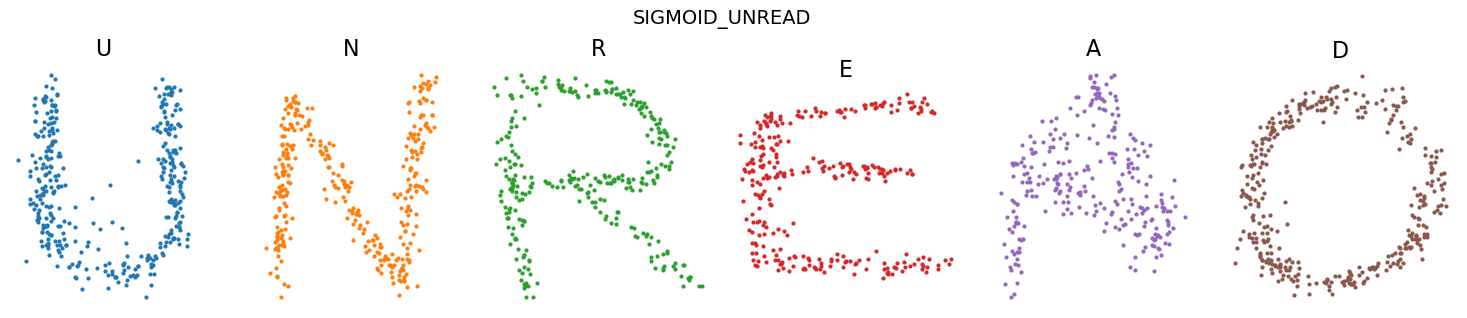

In [14]:
word = 'UNREAD'
pos = {ch: i for i, ch in enumerate(word)}
order = {c: pos[pick[c]] for c in letters_cl}

fig, axs = plt.subplots(1, 6, figsize=(15, 3.2))
for c, p in order.items():
    V = upright(c)
    a = axs[p]
    a.scatter(V[:, 0], V[:, 1], s=4, color=plt.cm.tab10(p))
    a.set_aspect('equal'); a.axis('off')
    a.set_title(pick[c], fontsize=16)
fig.suptitle('SIGMOID_' + word, fontsize=14)
plt.tight_layout()
plt.savefig('word.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
labels = fake[['listing_id', 'cluster']].copy()
labels['letter'] = labels.cluster.map(pick)
labels['position'] = labels.cluster.map(order) + 1
labels = labels.sort_values(['position', 'listing_id'])
labels.to_csv('labels.csv', index=False)
print(labels.shape)
labels.groupby(['position', 'letter']).size()

(1967, 4)


position  letter
1         U         370
2         N         334
3         R         311
4         E         304
5         A         280
6         D         368
dtype: int64

In [16]:
print('SIGMOID_' + word)

SIGMOID_UNREAD
